intro_to_Language_modeling part4 Continuation..
------

[video link](https://youtu.be/q8SA3rM6ckI)

[Additional details](https://github.com/MK2112/nn-zero-to-hero-notes/blob/578755b37de3d63854269dbcadef6670c8a5e254/N005%20-%20Makemore%204%20-%20Backprop%20Ninja/N005%20-%20Makemore_4.ipynb)

<ins>Goal</ins>

Understand backprop working - manual backprop instead of using PyTorch autograd's loss.backward():

Initial Setup
-----

In [2]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [3]:
# # optional - using exact version of pythorch from video
# %pip install --force-reinstall -v "torch==1.13.1" --quiet
# print(torch. __version__)

# # optional - debugging config
# %pip install ipdb --quiet
# import os
# os.environ['PYTHONBREAKPOINT'] = 'ipdb.set_trace'

In [4]:
# download the training data
!curl https://raw.githubusercontent.com/karpathy/makemore/refs/heads/master/names.txt -o names.txt -s

In [5]:
words = open('names.txt', 'r').read().splitlines()

In [6]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [7]:
# build the dataset for training,dev and test split
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):
  X, Y = [], []

  for w in words:
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr,  Ytr  = build_dataset(words[:n1])     # 80% training split
Xdev, Ydev = build_dataset(words[n1:n2])   # 10% dev split
Xte,  Yte  = build_dataset(words[n2:])     # 10% test split

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [8]:
# utility function we will use later when comparing manual gradients to PyTorch gradients
def cmp(s, dt, t): # here 'dt' is the manual derivative and 't' is the derivative calculated by pytorch
  ex = torch.all(dt == t.grad).item() # check if manual and pytorch derivative values are exactly equal
  app = torch.allclose(dt, t.grad) # check if manual and pytorch derivative values are close enough
  maxdiff = (dt - t.grad).abs().max().item() # if there is diff in manual and pytorch derivative, what is the diff
  print(f'{s:15s} | exact: {str(ex):5s} | approximate: {str(app):5s} | maxdiff: {maxdiff}')

Init Network
----

In [10]:
#init 2 layer MLP network

n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 64 # the number of neurons in the hidden layer of the MLP
g = torch.Generator().manual_seed(2147483647) # for reproducibility

# embedding tables for chars
C  = torch.randn((vocab_size, n_embd),            generator=g)

# Layer 1
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * (5/3)/((n_embd * block_size)**0.5)
b1 = torch.randn(n_hidden,                        generator=g) * 0.1 # using b1 just for fun, ideally it's useless when we use BatchNorm

# BatchNorm
bngain = torch.randn((1, n_hidden))*0.1 + 1.0
bnbias = torch.randn((1, n_hidden))*0.1 # setting to a small number instead of 0

# Layer 2
W2 = torch.randn((n_hidden, vocab_size),          generator=g) * 0.1
b2 = torch.randn(vocab_size,                      generator=g) * 0.1

# Note: I am initializating many of these parameters in non-standard ways
# because sometimes initializating with e.g. all zeros could mask an incorrect
# implementation of the backward pass.

parameters = [C, W1, b1, W2, b2, bngain, bnbias]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

4137


In [11]:
# creating a single mini batch for training
batch_size = 32
n = batch_size # a shorter variable also, for convenience
# construct a minibatch
ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y
Yb

tensor([ 8, 14, 15, 22,  0, 19,  9, 14,  5,  1, 20,  3,  8, 14, 12,  0, 11,  0,
        26,  9, 25,  0,  1,  1,  7, 18,  9,  3,  5,  9,  0, 18])

In [12]:
# forward pass, "chunkated" into smaller steps that are possible to backward one at a time

emb = C[Xb] # embed the characters into vectors
embcat = emb.view(emb.shape[0], -1) # concatenate the vectors

# Linear layer 1
hprebn = embcat @ W1 + b1 # hidden layer pre-activation

# BatchNorm layer - BatchNorm calculation splitted so as to check backprop manually
bnmeani = 1/n*hprebn.sum(0, keepdim=True)
bndiff = hprebn - bnmeani
bndiff2 = bndiff**2
bnvar = 1/(n-1)*(bndiff2).sum(0, keepdim=True) # note: Bessel's correction (dividing by n-1, not n) - basically using unbiased version in training and test phase
bnvar_inv = (bnvar + 1e-5)**-0.5
bnraw = bndiff * bnvar_inv
hpreact = bngain * bnraw + bnbias

# Non-linearity
h = torch.tanh(hpreact) # hidden layer

# Linear layer 2
logits = h @ W2 + b2 # output layer

# cross entropy loss (same as F.cross_entropy(logits, Yb)) - calculation splitted so as to check backprop manually
logit_maxes = logits.max(1, keepdim=True).values
norm_logits = logits - logit_maxes # subtract max for numerical stability
counts = norm_logits.exp()
counts_sum = counts.sum(1, keepdims=True)
counts_sum_inv = counts_sum**-1 # if I use (1.0 / counts_sum) instead then I can't get backprop to be bit exact...
probs = counts * counts_sum_inv
logprobs = probs.log()
loss = -logprobs[range(n), Yb].mean() # logprobs[range(n), Yb] extracts the log-probability value from the logprobs tensor that corresponds to the true next character (Yb[i])

# PyTorch backward pass
for p in parameters:
  p.grad = None
for t in [logprobs, probs, counts, counts_sum, counts_sum_inv, # afaik there is no cleaner way
          norm_logits, logit_maxes, logits, h, hpreact, bnraw,
         bnvar_inv, bnvar, bndiff2, bndiff, hprebn, bnmeani,
         embcat, emb]:
  t.retain_grad() # Enables this Tensor to have their grad populated during backward()
loss.backward()
loss

tensor(3.3410, grad_fn=<NegBackward0>)

# Exercise 1: backprop manually
----

In [13]:
print(f'{h.shape=} {W2.shape=} {b2.shape=}')
print(f'{hpreact.shape=} {bngain.shape=} {bnraw.shape=} {bnbias.shape}')
print(f'{emb.shape=} {embcat.shape=}')

h.shape=torch.Size([32, 64]) W2.shape=torch.Size([64, 27]) b2.shape=torch.Size([27])
hpreact.shape=torch.Size([32, 64]) bngain.shape=torch.Size([1, 64]) bnraw.shape=torch.Size([32, 64]) torch.Size([1, 64])
emb.shape=torch.Size([32, 3, 10]) embcat.shape=torch.Size([32, 30])


In [14]:
# This code cell performs the manual backpropagation for the neural network defined in the previous cells. It calculates the gradients for each variable in the network, starting from the final loss and working backward
# the cmp() function is used to compare the manually calculated gradients with the gradients computed by PyTorch's autograd (t.grad) to verify the correctness of the manual implementation.

### grads of loss calculation ###

# find derivative of logprobs(i.e dlogprobs) for equation 'loss = -logprobs[range(n), Yb].mean()'
# The loss is calculated as the negative mean of certain elements(i.e ones corresponds true next char) selected from the logprobs tensor.
# a simplified similar calculation loss = -(a + b + c)/3 . then applying sum-rule we get dloss/da = -1/3
dlogprobs = torch.zeros_like(logprobs) # init a zero tensor with shape of logprobs
dlogprobs[range(n), Yb] = -1.0/n
cmp('logprobs', dlogprobs, logprobs)

# find derivative of probs(i.e dprobs) for equation 'logprobs = probs.log()'
# The logprobs is calculated taking log of probs
# The LOCAL derivative dlogprobs/dprobs = 1/probs using log-rule https://www.wolframalpha.com/input?i=d%2Fdx+log%28x%29
# then dloss/dprobs = 1/probs * dlogprobs using chain rule
dprobs = (1.0 / probs) * dlogprobs
cmp('probs', dprobs, probs)

# find derivative of counts_sum_inv(i.e dcounts_sum_inv) for equation 'probs = counts * counts_sum_inv'
# The LOCAL derivative dprobs/dcounts_sum_inv = counts using https://www.wolframalpha.com/input?i=partial+derivative+of+x*y
# then dloss/dcounts_sum_inv = counts * dprobs using chain rule
dcounts_sum_inv = (counts * dprobs).sum(1, keepdim=True) # for detailed explanation https://youtu.be/q8SA3rM6ckI?list=PLAqhIrjkxbuWI23v9cThsA9GvCAUhRvKZ&t=1345
cmp('counts_sum_inv', dcounts_sum_inv, counts_sum_inv)

# find derivative of counts(i.e dcounts) for equation 'probs = counts * counts_sum_inv'
# The LOCAL derivative dprobs/dcounts = counts_sum_inv using https://www.wolframalpha.com/input?i=partial+derivative+of+x*y
# then dloss/dcounts = counts_sum_inv * dprobs using chain rule
dcounts = (counts_sum_inv * dprobs) # for detailed explanation https://youtu.be/q8SA3rM6ckI?list=PLAqhIrjkxbuWI23v9cThsA9GvCAUhRvKZ&t=1611
#cmp('counts', dcounts, counts) # cant check it here as counts is used multiple times in two diff expression

# find derivative of counts_sum(i.e dcounts_sum) for equation 'counts_sum_inv = counts_sum**-1' or 'counts_sum_inv = 1.0 / counts_sum'
# The LOCAL derivative dcounts_sum_inv/dcounts_sum = -counts_sum**-2 or -1/counts_sum**2 using https://www.wolframalpha.com/input?i=d%2Fdx+x**-1
# then dloss/dcounts_sum = -counts_sum**-2 * dcounts_sum_inv using chain rule
dcounts_sum = (-counts_sum**-2) * dcounts_sum_inv
cmp('counts_sum', dcounts_sum, counts_sum)

# find derivative of counts(i.e dcounts) for equation 'counts_sum = counts.sum(1, keepdims=True)'
# The LOCAL derivative ddcounts_sum/dcounts = 1 using https://www.wolframalpha.com/input?i=d%2Fdx+x%2By
# then dloss/dcounts = 1 * dcounts_sum using chain rule
dcounts += torch.ones_like(counts) * dcounts_sum # here we use += so as to add with the previously calculated dcounts
cmp('counts', dcounts, counts)

# find derivative of norm_logits(i.e dnorm_logits) for equation 'counts = norm_logits.exp()'
# The LOCAL derivative dcounts/dnorm_logits = norm_logits.exp() using exponent-rule
# then dloss/dnorm_logits = norm_logits.exp() * dcounts using chain rule
dnorm_logits = (norm_logits.exp()) * dcounts
cmp('norm_logits', dnorm_logits, norm_logits)

# find derivative of logits(i.e dlogits) for equation 'norm_logits = logits - logit_maxes'
# The LOCAL derivative dnorm_logits/dlogits = 1 using https://www.wolframalpha.com/input?i=d%2Fdx++x-y
# then dloss/dlogits = 1 * dnorm_logits using chain rule
dlogits = dnorm_logits.clone() # or (1.0) * dnorm_logits.clone()
# cmp('logits', dlogits, logits) # not the final derivative of logits

# find derivative of logit_maxes(i.e dlogit_maxes) for equation 'norm_logits = logits - logit_maxes'
# The LOCAL derivative dnorm_logits/dlogit_maxes = -1 using https://www.wolframalpha.com/input?i=d%2Fdy++x-y
# then dloss/dlogit_maxes = -1 * dnorm_logits using chain rule
dlogit_maxes = (-dnorm_logits).sum(1, keepdim=True) # or (-1.0) * (dnorm_logits).sum(1, keepdim=True)
cmp('logit_maxes', dlogit_maxes, logit_maxes)

# find derivative of logits(i.e dlogits) for equation 'logit_maxes = logits.max(1, keepdim=True).values'
# The LOCAL derivative dlogit_maxes/dlogits = 1
# then dloss/dlogits = 1 *dlogit_maxes using chain rule
# dlogits = torch.zeros_like(logits)
# dlogits[range(n), logits.max(1).indices] = 1 # setting the derivative of the logit with max value as 1. so in a singe row in dlogits , there will be one '1' and reste as '0'
# dlogits += dlogits * dlogit_maxes
dlogits += F.one_hot(logits.max(1).indices, num_classes=logits.shape[1]) * dlogit_maxes
cmp('logits', dlogits, logits) # for detailed explanation https://youtu.be/q8SA3rM6ckI?list=PLAqhIrjkxbuWI23v9cThsA9GvCAUhRvKZ&t=2310

### grads of layer2 ###

# find derivative of h(i.e dh) for equation 'logits = h @ W2 + b2'
# the backpass of matrix multipy is a matrix multipy itself
# then dloss/dh = dlogits @ W2.T - for detailed explanation https://youtu.be/q8SA3rM6ckI?list=PLAqhIrjkxbuWI23v9cThsA9GvCAUhRvKZ&t=2507
dh = dlogits @ W2.T # here we are Transposing to match dimensions
cmp('h', dh, h)

# find derivative of W2(i.e dW2) for equation 'logits = h @ W2 + b2'
# the backpass of matrix multipy is a matrix multipy itself
# then dloss/dW2 = h.T @ dlogits - for detailed explanation https://youtu.be/q8SA3rM6ckI?list=PLAqhIrjkxbuWI23v9cThsA9GvCAUhRvKZ&t=2507
dW2 = h.T @ dlogits # here we are Transposing to match dimensions
cmp('W2', dW2, W2)

# find derivative of b2(i.e db2) for equation 'logits = h @ W2 + b2'
# then dloss/db2 is the sum over dlogits - for detailed explanation https://youtu.be/q8SA3rM6ckI?list=PLAqhIrjkxbuWI23v9cThsA9GvCAUhRvKZ&t=2507
db2 = dlogits.sum(0)
cmp('b2', db2, b2)

### grads of tanh hidden layer ###

# find derivative of hpreact(i.e dhpreact) for equation 'h = torch.tanh(hpreact)'
# The LOCAL derivative dh/dhpreact = '1 - h**2' or '1 - tanh^2(x)' or '1.0 / (torch.cosh(x))'
# then dloss/dhpreact = (1 - h**2) * dh using chain rule
dhpreact = (1.0 - h**2) * dh # or dhpreact = (1.0 / (torch.cosh(hpreact))) * dh
cmp('hpreact', dhpreact, hpreact)

### grads of BatchNorm ###

# find derivative of bngain(i.e dbngain) for equation 'hpreact = bngain * bnraw + bnbias'
# The LOCAL derivative dhpreact/dbngain = bnraw using https://www.wolframalpha.com/input?i=partial+derivative+of+x*y
# then dloss/bngain = bnraw * dhpreact using chain rule
dbngain = (bnraw * dhpreact).sum(0,keepdim=True) # summing to match resulting dimensions
cmp('bngain', dbngain, bngain)

# find derivative of bnraw(i.e dbnraw) for equation 'hpreact = bngain * bnraw + bnbias'
# The LOCAL derivative dhpreact/dbnraw = bngain using https://www.wolframalpha.com/input?i=partial+derivative+of+x*y
# then dloss/dbnraw = bngain * dhpreact using chain rule
dbnraw = bngain * dhpreact
cmp('bnraw', dbnraw, bnraw)

# find derivative of bnbias(i.e dbnbias) for equation 'hpreact = bngain * bnraw + bnbias'
# The LOCAL derivative dhpreact/dbnbias = 1 using https://www.wolframalpha.com/input?i=d%2Fdx+x%2By
# then dloss/bnbias = 1 * dhpreact using chain rule
dbnbias = dhpreact.sum(0,keepdim=True)
cmp('bnbias', dbnbias, bnbias)

# find derivative of bndiff(i.e dbndiff) for equation 'bnraw = bndiff * bnvar_inv'
# The LOCAL derivative dbnraw/dbndiff = bnvar_inv using https://www.wolframalpha.com/input?i=partial+derivative+of+x*y
# then dloss/bnbias = bnvar_inv * dbnraw using chain rule
dbndiff = bnvar_inv * dbnraw
#cmp('bndiff', dbndiff, bndiff)

# find derivative of bnvar_inv(i.e dbnvar_inv) for equation 'bnraw = bndiff * bnvar_inv'
# The LOCAL derivative dbnraw/dbnvar_inv = bnvar_inv using https://www.wolframalpha.com/input?i=partial+derivative+of+x*y
# then dloss/dbnvar_inv = bndiff * dbnraw using chain rule
dbnvar_inv = (bndiff * dbnraw).sum(0, keepdim=True) # summing to match resulting dimensions
cmp('bnvar_inv', dbnvar_inv, bnvar_inv)

# find derivative of bnvar(i.e dbnvar) for equation 'bnvar_inv = (bnvar + 1e-5)**-0.5'
# consider above equation as y = (x+2)**-0.5 , so we can split it into two
# 1. inner equation say inn = x+2 - by applying power-rule(on x) and constant-rule(on 2) we get derivative dinn/dx = 1 + 0 = 1
# 2. outter equation say out = inn**-0.5 by applying power-rule we get derivative dout/dinn = -0.5 *(inn)**-1.5
# 3. Then using chain rule final derivative dy/dx = dinn/dx * dout/dinn = (-0.5 *(inn)**-1.5) * 1 = -0.5 *(inn)**-1.5
# The LOCAL derivative dbnvar_inv/dbnvar = -0.5 *(bnvar + 1e-5)**-1.5
# then dloss/dbnvar = (-0.5 *(bnvar + 1e-5)**-1.5) * dbnvar_inv using chain rule
dbnvar = (-0.5 *(bnvar + 1e-5)**-1.5) * dbnvar_inv
cmp('bnvar', dbnvar, bnvar)

# find derivative of bndiff2(i.e dbndiff2) for equation 'bnvar = 1/(n-1)*(bndiff2).sum(0, keepdim=True)'
# The equation can be seeen as two two operations
# 1. Summation: sum_bndiff2 = bndiff2.sum(0, keepdim=True)
# 2. Scaling: bnvar = (1/(n-1)) * sum_bndiff2
# based on scaling equation,find local derivative of bnvar which is '1/(n-1)' - based on https://www.wolframalpha.com/input?i=partial+derivative+of+x*y
# based on summation equation,find local derivative of bndiff2 which is 1 - the local derivative of a sum with respect to each of its individual terms is always 1(applying constant-rule and power-rule)
# The LOCAL derivative dbnvar/dbndiff2 using chain rule = 1/(n-1) * 1 = 1/(n-1) * torch.ones_like(bndiff2)
# then dloss/dbndiff2 = (1.0/(n-1))*torch.ones_like(bndiff2) * dbnvar using chain rule
dbndiff2 = (1.0/(n-1))*torch.ones_like(bndiff2) * dbnvar
cmp('bndiff2', dbndiff2, bndiff2)

# find derivative of bndiff(i.e dbndiff) for equation 'bndiff2 = bndiff**2'
# The LOCAL derivative dbndiff2/dbndiff = 2*bndiff using power-rule
# then dloss/dbndiff = 2*bndiff * dbndiff2 using chain rule
dbndiff += (2*bndiff) * dbndiff2
cmp('bndiff', dbndiff, bndiff)

# find derivative of hprebn(i.e dhprebn) for equation 'bndiff = hprebn - bnmeani'
# The LOCAL derivative dbndiff/dhprebn = 1 based on https://www.wolframalpha.com/input?i=d%2Fdx+x-y
# then dloss/dhprebn = 1 * dbndiff  using chain rule
dhprebn = dbndiff.clone()
#cmp('hprebn', dhprebn, hprebn)

# find derivative of bnmeani(i.e dbnmeani) for equation 'bndiff = hprebn - bnmeani'
# The LOCAL derivative dbndiff/dbnmeani = -1 based on https://www.wolframalpha.com/input?i=d%2Fdy+x-y
# then dloss/dbnmeani = -1 * dbndiff  using chain rule
dbnmeani = -dbndiff.sum(0)
cmp('bnmeani', dbnmeani, bnmeani)#---------------

# find derivative of hprebn(i.e dhprebn) for equation 'bnmeani = 1/n*hprebn.sum(0, keepdim=True)'
# The equation can be seeen as two two operations
# 1. Summation: sum_hprebn = hprebn.sum(0, keepdim=True)
# 2. Scaling: bnmeani = (1/n) * sum_hprebn
# based on scaling equation,find local derivative of sum_hprebn which is '1/n' - based on https://www.wolframalpha.com/input?i=partial+derivative+of+x*y
# based on summation equation,find local derivative of hprebn which is 1 - the local derivative of a sum with respect to each of its individual terms is always 1(applying constant-rule and power-rule)
# The LOCAL derivative dbnmeani/dhprebn using chain rule = 1/n * 1 = 1/n * torch.ones_like(hprebn)
# then dloss/dhprebn = 1/n * torch.ones_like(hprebn) * dbnmeani using chain rule
dhprebn += 1.0/n * (torch.ones_like(hprebn) * dbnmeani)
cmp('hprebn',dhprebn,hprebn)

### grads of layer1 ###

# find derivative of embcat(i.e dembcat) for equation 'hprebn = embcat @ W1 + b1'
# The equation can be seeen as two two operations
# 1. matrix-multiplication: mul = embcat @ W1
# 2. addition: mul + b1
# based on addition equation,find local derivative of mul which is 1  - https://www.wolframalpha.com/input?i=partial+derivative+of+x%2By
# based on matrix-multiplication,find local derivative of embcat which is W1.T - local derivatives of a param in matrix-multiplication is the transpose of the other matrix parameter.
# The LOCAL derivative dhprebn/dembcat using chain rule = 1 * W1.T
# then dloss/dembcat = dhprebn @ W1.T using chain rule
dembcat = dhprebn @ W1.T
cmp('embcat', dembcat, embcat)

# find derivative of W1(i.e dW1) for equation 'hprebn = embcat @ W1 + b1'
# The LOCAL derivative calculation similar to above
# then dloss/dW1 =  embact.T @ dhprebn using chain rule
dW1 = embcat.T @ dhprebn
cmp('W1', dW1, W1)

# find derivative of b1(i.e db1) for equation 'hprebn = embcat @ W1 + b1'
# The equation can be seeen as two two operations
# 1. matrix-multiplication: mul = embcat @ W1
# 2. addition: mul + b1
# based on addition equation,find local derivative of b1 which is 1  - https://www.wolframalpha.com/input?i=partial+derivative+of+x%2By
# based on matrix-multiplication - When differentiating hprebn with respect to b1, embcat @ W1 is treated as a constant so the derivat will be 1 https://www.wolframalpha.com/input?i=d%2Fdx+x%2B5
# The LOCAL derivative dhprebn/db1 using chain rule = 1 * 1 = 1
# then dloss/db1 =  1 * hprebn using chain rule
db1 = dhprebn.sum(0)
cmp('b1', db1, b1)

# find derivative of emb(i.e demb) for equation 'embcat = emb.view(emb.shape[0], -1)'
# The .view() operation is essentially a reshape, and reshaping itself doesn't change the values, just their arrangement. Therefore, the gradient simply needs to be reshaped back to the original shape of emb
demb = dembcat.view(emb.shape)
cmp('emb', demb, emb)

# find derivative of C(i.e dC) for equation 'emb = C[Xb]'
# The operation emb = C[Xb] is an indexing operation. The gradient demb needs to be scattered back to the original tensor C based on the indices in Xb
dC = torch.zeros_like(C)
for k in range(Xb.shape[0]): # 0 to 32
  for j in range(Xb.shape[1]): # 0 to 3
    ix = Xb[k,j] # index of a char in an input row
    dC[ix] += demb[k,j]
cmp('C', dC, C)

logprobs        | exact: True  | approximate: True  | maxdiff: 0.0
probs           | exact: True  | approximate: True  | maxdiff: 0.0
counts_sum_inv  | exact: True  | approximate: True  | maxdiff: 0.0
counts_sum      | exact: True  | approximate: True  | maxdiff: 0.0
counts          | exact: True  | approximate: True  | maxdiff: 0.0
norm_logits     | exact: True  | approximate: True  | maxdiff: 0.0
logit_maxes     | exact: True  | approximate: True  | maxdiff: 0.0
logits          | exact: True  | approximate: True  | maxdiff: 0.0
h               | exact: True  | approximate: True  | maxdiff: 0.0
W2              | exact: True  | approximate: True  | maxdiff: 0.0
b2              | exact: True  | approximate: True  | maxdiff: 0.0
hpreact         | exact: False | approximate: True  | maxdiff: 4.656612873077393e-10
bngain          | exact: False | approximate: True  | maxdiff: 3.725290298461914e-09
bnraw           | exact: False | approximate: True  | maxdiff: 4.656612873077393e-10
bnbias  

In [17]:
# Excercise 2: Manual backprop through cross_entropy (instead of the above )

# forward pass of loss calculation using cross_entropy
# Internally, cross_entropy does these steps to calculate loss
# 1. Softmax: Applies the softmax function to the logits to convert them into predicted probabilities for each class. These probabilities are between 0 and 1 and sum up to 1
# 2. Log: Takes the natural logarithm of the predicted probabilities. This gives log-probabilities.
# 3. Selection: Selects the log-probability that corresponds to the true target class for each input example
# 4. Negative Mean: Calculates the mean of these selected log-probabilities across the batch and negates it to get the final cross-entropy loss

loss_fast = F.cross_entropy(logits, Yb)
print(loss_fast.item(), 'diff:', (loss_fast - loss).item())

## Its back pass calculated ##
# backprop steps
# 1. Backprop through Negative Mean -
# find derivative of logits(i.e dlogits) for equation 'loss_fast = F.cross_entropy(logits, Yb)'
dlogits = F.softmax(logits, 1) #This calculates the predicted probabilities by applying the softmax function to the logits along dimension 1 (the dimension corresponding to the vocabulary size).
# This is the core step for finding the manual gradient of the logits
dlogits[range(n), Yb] -= 1 # This line implements the - 1 part for the true classes at the correct indices
dlogits /= n #Since the cross-entropy loss includes a mean() operation (division by n), the gradient also needs to be scaled by 1/n due to the Constant Multiple Rule
cmp('logits', dlogits, logits)# I can only get approximate to be true, my maxdiff is 6e-9

3.3410491943359375 diff: 2.384185791015625e-07
logits          | exact: False | approximate: True  | maxdiff: 5.820766091346741e-09


32

probablity after softaxtensor([0.0697, 0.0910, 0.0192, 0.0482, 0.0209, 0.0859, 0.0223, 0.0353, 0.0179,
        0.0313, 0.0361, 0.0368, 0.0370, 0.0288, 0.0351, 0.0137, 0.0093, 0.0178,
        0.0172, 0.0508, 0.0503, 0.0220, 0.0264, 0.0702, 0.0597, 0.0271, 0.0202],
       grad_fn=<SelectBackward0>)
gradtensor([ 0.0697,  0.0910,  0.0192,  0.0482,  0.0209,  0.0859,  0.0223,  0.0353,
        -0.9821,  0.0313,  0.0361,  0.0368,  0.0370,  0.0288,  0.0351,  0.0137,
         0.0093,  0.0178,  0.0172,  0.0508,  0.0503,  0.0220,  0.0264,  0.0702,
         0.0597,  0.0271,  0.0202], grad_fn=<MulBackward0>)


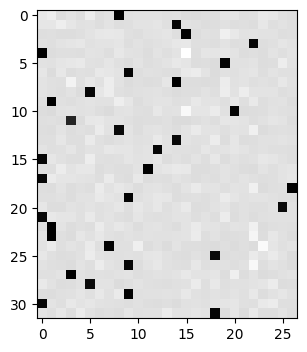

In [27]:
# checking predicted probabilities after softmax and the calculated gradients of the logits
print(f'probablity after softax{F.softmax(logits, 1)[0]}')
print(f'grad{dlogits[0] * n}') # here multiplying  gradient by the batch size(32). Remember that the dlogits gradient was scaled by 1/n because of the mean operation in the loss. Multiplying by n essentially shows the sum of the local gradients before the mean was taken
plt.figure(figsize=(4, 4))
plt.imshow(dlogits.detach(), cmap='gray')

In [28]:
# Excercise 3: Manual backprop through BatchNorm

# forward pass of BatchNorm - using short version than eralier one
# Internally, BatchNorm does these steps in forward pass
# 1. Calculate Batch Mean: Compute the mean of the input across the batch dimension - here its 'hprebn.mean(0, keepdim=True)'
# 2. Center the Data: Subtract the calculated batch mean from each element of the input.
#    This shifts the distribution so it has a mean of zero - here its '(hprebn - hprebn.mean(0, keepdim=True))'
# 3. Calculate Batch Variance(similar to standar deviation calculation): Compute the variance of the centered data across the batch dimension, typically using Bessel's correction (dividing by n-1 instead of n) during training for an unbiased estimate
#    - here its 'hprebn.var(0, keepdim=True, unbiased=True)' This function call calculates the variance of the hprebn tensor along dimension 0
# 4. Calculate Inverse Standard Deviation: Take the square root of the batch variance to get the standard deviation, and then compute its inverse (1 divided by the standard deviation), adding a small epsilon
#    - here its '1 / torch.sqrt(hprebn.var(0, keepdim=True, unbiased=True) + 1e-5)' . + 1e-5' a small epsilon(1e-5) added for numerical stability to prevent division by zero if the variance is exactly zero
# 5. Normalize (Scale by Inverse Std Dev): Multiply the centered data by the inverse standard deviation. This scales the distribution so it has a variance of one (and thus a standard deviation of one). The data at this point has a mean of zero and a variance of one.
#    - here its '(hprebn - hprebn.mean(0, keepdim=True)) / torch.sqrt(hprebn.var(0, keepdim=True, unbiased=True) + 1e-5)'
# 6. Scale and Shift (Apply Learnable Parameters): Multiply the normalized data by a learnable scale parameter (often called "gain" or "gamma") and add a learnable shift parameter (often called "bias" or "beta"). These parameters allow the network to learn the optimal mean and variance for each feature dimension, rather than being strictly forced to have a mean of 0 and variance of 1
#    - here its 'bngain * (...) + bnbias'

hpreact_fast = bngain * (hprebn - hprebn.mean(0, keepdim=True)) / torch.sqrt(hprebn.var(0, keepdim=True, unbiased=True) + 1e-5) + bnbias
print('max diff:', (hpreact_fast - hpreact).abs().max())

## Its back pass calculated ##
dhprebn = bngain*bnvar_inv/n * (n*dhpreact - dhpreact.sum(0) - n/(n-1)*bnraw*(dhpreact*bnraw).sum(0))
cmp('hprebn', dhprebn, hprebn) # I can only get approximate to be true, my maxdiff is 9e-10

max diff: tensor(4.7684e-07, grad_fn=<MaxBackward1>)
hprebn          | exact: False | approximate: True  | maxdiff: 9.313225746154785e-10


In [29]:
# Exercise 4: putting it all together
# training with the manual backprop(using above fast versions of BatchNorm and )

### Init the model ###
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C  = torch.randn((vocab_size, n_embd),            generator=g)
# Layer 1
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * (5/3)/((n_embd * block_size)**0.5)
b1 = torch.randn(n_hidden,                        generator=g) * 0.1
# Layer 2
W2 = torch.randn((n_hidden, vocab_size),          generator=g) * 0.1
b2 = torch.randn(vocab_size,                      generator=g) * 0.1
# BatchNorm parameters
bngain = torch.randn((1, n_hidden))*0.1 + 1.0
bnbias = torch.randn((1, n_hidden))*0.1

parameters = [C, W1, b1, W2, b2, bngain, bnbias]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

### training ###
max_steps = 200000
batch_size = 32
n = batch_size # convenience
lossi = []

with torch.no_grad(): # optional: just telling pytorch not to set grads

  for i in range(max_steps):

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

    emb = C[Xb] # embed the characters into vectors
    embcat = emb.view(emb.shape[0], -1) # concatenate the vectors

    # Linear layer
    hprebn = embcat @ W1 + b1 # hidden layer pre-activation

    # BatchNorm layer
    bnmean = hprebn.mean(0, keepdim=True)
    bnvar = hprebn.var(0, keepdim=True, unbiased=True)
    bnvar_inv = (bnvar + 1e-5)**-0.5
    bnraw = (hprebn - bnmean) * bnvar_inv
    hpreact = bngain * bnraw + bnbias

    # Non-linearity
    h = torch.tanh(hpreact) # hidden layer
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, Yb) # loss function

    # backward pass
    for p in parameters:
      p.grad = None
    #loss.backward() # use this for correctness comparisons, delete it later!

    # loss backprop
    dlogits = F.softmax(logits, 1)
    dlogits[range(n), Yb] -= 1
    dlogits /= n
    # 2nd layer backprop
    dh = dlogits @ W2.T
    dW2 = h.T @ dlogits
    db2 = dlogits.sum(0)
    # tanh
    dhpreact = (1.0 - h**2) * dh
    # batchnorm backprop
    dbngain = (bnraw * dhpreact).sum(0, keepdim=True)
    dbnbias = dhpreact.sum(0, keepdim=True)
    dhprebn = bngain*bnvar_inv/n * (n*dhpreact - dhpreact.sum(0) - n/(n-1)*bnraw*(dhpreact*bnraw).sum(0))
    # 1st layer
    dembcat = dhprebn @ W1.T
    dW1 = embcat.T @ dhprebn
    db1 = dhprebn.sum(0)
    # embedding
    demb = dembcat.view(emb.shape)
    dC = torch.zeros_like(C)
    for k in range(Xb.shape[0]):
      for j in range(Xb.shape[1]):
        ix = Xb[k,j]
        dC[ix] += demb[k,j]
    grads = [dC, dW1, db1, dW2, db2, dbngain, dbnbias]
    # -----------------

    # update
    lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
    for p, grad in zip(parameters, grads):
      #p.data += -lr * p.grad # old way of cheems doge (using PyTorch grad from .backward())
      p.data += -lr * grad # new way of swole doge TODO: enable

    # track stats
    if i % 10000 == 0: # print every once in a while
      print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

  #   if i >= 100: # TODO: delete early breaking when you're ready to train the full net
  #     break

12297
      0/ 200000: 3.7821
  10000/ 200000: 2.2054
  20000/ 200000: 2.3511
  30000/ 200000: 2.4649
  40000/ 200000: 1.9817
  50000/ 200000: 2.2964
  60000/ 200000: 2.4122
  70000/ 200000: 2.0293
  80000/ 200000: 2.3478
  90000/ 200000: 2.1538
 100000/ 200000: 2.0134
 110000/ 200000: 2.2527
 120000/ 200000: 1.9204
 130000/ 200000: 2.4296
 140000/ 200000: 2.3436
 150000/ 200000: 2.2220
 160000/ 200000: 1.9493
 170000/ 200000: 1.8636
 180000/ 200000: 2.0567
 190000/ 200000: 1.9101


In [30]:
# calibrate the batch norm at the end of training
# measuring the bnmean and bnvar (ideally it should habe been calculated the training loop it)
with torch.no_grad():
  # pass the training set through
  emb = C[Xtr]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 + b1
  # measure the mean/std over the entire training set
  bnmean = hpreact.mean(0, keepdim=True)
  bnvar = hpreact.var(0, keepdim=True, unbiased=True)

In [31]:
# evaluate train and val loss

@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  emb = C[x] # (N, block_size, n_embd)
  embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
  hpreact = embcat @ W1 + b1
  hpreact = bngain * (hpreact - bnmean) * (bnvar + 1e-5)**-0.5 + bnbias
  h = torch.tanh(hpreact) # (N, n_hidden)
  logits = h @ W2 + b2 # (N, vocab_size)
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.071672201156616
val 2.1092183589935303


In [32]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):

    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      # ------------
      # forward pass:
      # Embedding
      emb = C[torch.tensor([context])] # (1,block_size,d)
      embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
      hpreact = embcat @ W1 + b1
      hpreact = bngain * (hpreact - bnmean) * (bnvar + 1e-5)**-0.5 + bnbias
      h = torch.tanh(hpreact) # (N, n_hidden)
      logits = h @ W2 + b2 # (N, vocab_size)
      # ------------
      # Sample
      probs = F.softmax(logits, dim=1)
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0:
        break

    print(''.join(itos[i] for i in out))

mora.
mayah.
see.
mad.
ryll.
renma.
jendraege.
dejadielin.
shi.
jen.
eden.
estanar.
kayzion.
kamin.
shubergiai.
jest.
jair.
jennex.
ter.
fous.
